# Chapitre 3 - Cours 3 : LAR, PCR, PLS et comparaison des méthodes

Ce dernier notebook de cours couvre les sections 3.4.4 à 3.6 du livre :

1. la **régression du moindre angle** (LAR, *least angle regression*), son lien avec le
   lasso et ses degrés de liberté (figures 3.14, 3.15) ;
2. les méthodes à **directions dérivées** : régression sur composantes principales (PCR)
   et moindres carrés partiels (PLS) (figure 3.17, algorithme 3.3) ;
3. la **comparaison** de toutes les méthodes du chapitre sur la prostate (figure 3.7
   complète, tableau 3.3) et sur un problème jouet à deux variables (figure 3.18).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

import pandas as pd
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import lars_path
from esl import ch03_regression as cr

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)


def show(df):
    """Affiche un tableau arrondi, les coefficients absents (NaN) laissés en blanc."""
    return df.round(3).astype(object).where(df.notna(), "")

In [2]:
Xtr, ytr, Xte, yte, names = cr.load_prostate_standardized()
N, p = Xtr.shape
fit_ls = cr.ols_fit(Xtr, ytr)


def test_error(b0, beta):
    """Erreur quadratique moyenne sur l'échantillon de test."""
    return np.mean((yte - b0 - Xte @ beta) ** 2)

## 1. Régression du moindre angle (LAR)

LAR est une version « démocratique » de la sélection pas à pas ascendante. Au lieu
d'ajouter **entièrement** une variable au modèle, elle n'en ajoute que « la part
méritée » (algorithme 3.2 du livre) :

1. Standardiser les prédicteurs (moyenne nulle, norme 1). Partir de $\mathbf{r} = \mathbf{y} - \bar y$
   et $\beta_1 = \dots = \beta_p = 0$.
2. Trouver le prédicteur $\mathbf{x}_j$ le plus corrélé à $\mathbf{r}$.
3. Faire croître $\beta_j$ de 0 vers son coefficient des moindres carrés
   $\langle\mathbf{x}_j, \mathbf{r}\rangle$, **jusqu'à ce qu'un autre** prédicteur
   $\mathbf{x}_k$ ait autant de corrélation avec le résidu courant.

4. Faire évoluer $\beta_j$ et $\beta_k$ dans la direction de leur coefficient des moindres
   carrés **joint** (régression du résidu sur $(\mathbf{x}_j, \mathbf{x}_k)$), jusqu'à ce
   qu'un troisième prédicteur $\mathbf{x}_l$ rattrape la même corrélation.
5. Continuer ainsi jusqu'à ce que tous les prédicteurs soient entrés. Après
   $\min(N-1, p)$ étapes, on obtient la solution des moindres carrés complète.

**La direction de l'étape $k$.** Notons $\mathcal{A}_k$ l'ensemble **actif** au début de
l'étape $k$, $\mathbf{X}_{\mathcal{A}_k}$ les colonnes correspondantes et
$\mathbf{r}_k = \mathbf{y} - \mathbf{X}_{\mathcal{A}_k}\beta_{\mathcal{A}_k}$ le résidu.
La direction des coefficients est (éq. (3.55))

$$
\delta_k = (\mathbf{X}_{\mathcal{A}_k}^T\mathbf{X}_{\mathcal{A}_k})^{-1}\mathbf{X}_{\mathcal{A}_k}^T\mathbf{r}_k ,
$$

et l'on pose $\beta_{\mathcal{A}_k}(\alpha) = \beta_{\mathcal{A}_k} + \alpha\,\delta_k$. Les
valeurs ajustées évoluent selon $\hat{\mathbf{f}}_k(\alpha) = \hat{\mathbf{f}}_k + \alpha\,\mathbf{u}_k$
avec $\mathbf{u}_k = \mathbf{X}_{\mathcal{A}_k}\delta_k$.

**Pourquoi les corrélations restent à égalité.** Supposons qu'au début de l'étape toutes
les variables actives aient la même corrélation absolue $C$ avec le résidu :
$\mathbf{X}_{\mathcal{A}}^T\mathbf{r}_k = C\,\mathbf{s}$ où $\mathbf{s}$ est le vecteur
des signes. Alors $\mathbf{X}_{\mathcal{A}}^T\mathbf{u}_k = \mathbf{X}_{\mathcal{A}}^T\mathbf{X}_{\mathcal{A}}\delta_k = \mathbf{X}_{\mathcal{A}}^T\mathbf{r}_k = C\,\mathbf{s}$, donc

$$
\mathbf{X}_{\mathcal{A}}^T\bigl(\mathbf{r}_k - \alpha\,\mathbf{u}_k\bigr) = (1 - \alpha)\,C\,\mathbf{s} :
$$

les corrélations actives décroissent **ensemble**, linéairement, et restent égales en
valeur absolue. Comme $\mathbf{u}_k$ fait le même produit scalaire avec chaque
$s_j\mathbf{x}_j$ (de norme 1), il fait **le même angle** avec chacune : c'est l'origine du
nom « moindre angle » (exercice 3.24).

> **Remarque (pas de petits pas).** Les corrélations des variables inactives
> $\langle\mathbf{x}_\ell, \mathbf{r}_k - \alpha\mathbf{u}_k\rangle$ sont aussi affines en
> $\alpha$ : on calcule **exactement** la valeur de $\alpha$ où l'une d'elles rattrape les
> variables actives (exercice 3.25). LAR calcule ainsi tout son chemin en $p$ étapes, pour
> le coût d'une régression par moindres carrés.

### 1.1 Illustration sur données simulées (figure 3.14)

Comme le livre, prenons un jeu simulé à six prédicteurs. On trace la corrélation absolue
$|\langle\mathbf{x}_j, \mathbf{r}\rangle|$ de chaque prédicteur avec le résidu courant, en
fonction de la **longueur d'arc $L_1$** du chemin des coefficients (somme des
$\lVert\Delta\beta\rVert_1$ d'une étape à l'autre).

In [3]:
rng = np.random.RandomState(13)
Ns, ps = 60, 6
Xsim = rng.randn(Ns, ps) @ rng.randn(ps, ps)
ysim = Xsim @ (2 * rng.randn(ps)) + 4 * rng.randn(Ns)
Xsim = Xsim - Xsim.mean(0)
Xsim = Xsim / np.linalg.norm(Xsim, axis=0)          # colonnes de norme 1
ysim = ysim - ysim.mean()
coefs_lar, corr_lar, actions_lar = cr.lars(Xsim, ysim, method="lar")
arc = np.r_[0, np.cumsum(np.abs(np.diff(coefs_lar, axis=0)).sum(1))]
abs_corr = np.abs((ysim[:, None] - Xsim @ coefs_lar.T).T @ Xsim)     # (nœuds, p)
print("ordre d'entrée :", ["x%d" % (j + 1) for j in actions_lar])

ordre d'entrée : ['x6', 'x2', 'x3', 'x4', 'x1', 'x5']


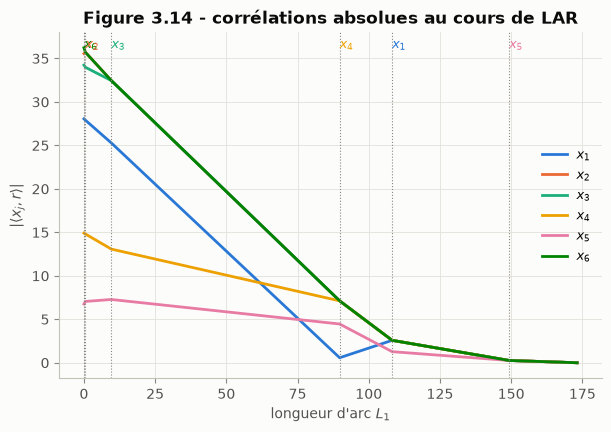

In [4]:
fig, ax = plt.subplots()
for j in range(ps):
    ax.plot(arc, abs_corr[:, j], color=COLORS[j], label="$x_%d$" % (j + 1))
for k, (a_k, j) in enumerate(zip(arc[:-1], actions_lar)):
    ax.axvline(a_k, color=GRAY, linestyle=":", linewidth=0.8)
    ax.text(a_k, ax.get_ylim()[1] * 0.98, "$x_%d$" % (j + 1), color=COLORS[j], ha="left", va="top", fontsize=9)
ax.set_title("Figure 3.14 - corrélations absolues au cours de LAR")
ax.set_xlabel("longueur d'arc $L_1$"); ax.set_ylabel(r"$|\langle x_j, r\rangle|$")
ax.legend(loc="center right")
plt.show()

Chaque variable qui entre rejoint la courbe commune des corrélations maximales, qui décroît
par morceaux linéaires jusqu'à 0 (solution des moindres carrés, où le résidu est orthogonal
à toutes les entrées). Vérifions l'égalité des angles à une étape intermédiaire :

In [5]:
k = 3
r_k = ysim - Xsim @ coefs_lar[k]
delta = coefs_lar[k + 1] - coefs_lar[k]
u = Xsim @ delta
active = [j for j in actions_lar[:k + 1]]
cos = Xsim[:, active].T @ u / np.linalg.norm(u)
print("variables actives :", ["x%d" % (j + 1) for j in active])
print("corrélations avec le résidu :", (Xsim[:, active].T @ r_k).round(4))
print("cosinus des angles (x_j, u_k) :", cos.round(4))

variables actives : ['x6', 'x2', 'x3', 'x4']
corrélations avec le résidu : [ 7.1213  7.1213  7.1213 -7.1213]
cosinus des angles (x_j, u_k) : [ 0.4963  0.4963  0.4963 -0.4963]


### 1.2 LAR et lasso (algorithme 3.2a, figure 3.15)

Les chemins de LAR et du lasso sont souvent **identiques**. Ils diffèrent seulement
lorsqu'un coefficient non nul **traverse zéro**. La modification qui rend LAR exactement
égal au lasso est :

> **4a.** Si un coefficient non nul atteint zéro, retirer sa variable de l'ensemble actif et
> recalculer la direction des moindres carrés joints.

*Explication.* Pour le lasso (pénalité $\lambda\lVert\beta\rVert_1$, critère
$\frac12\lVert\mathbf{y} - \mathbf{X}\beta\rVert^2$), les conditions d'optimalité
(éq. (3.58)–(3.59)) imposent, pour chaque variable active,
$\langle\mathbf{x}_j, \mathbf{y} - \mathbf{X}\beta\rangle = \lambda\cdot\mathrm{signe}(\beta_j)$ :
la corrélation doit avoir **le même signe** que le coefficient. LAR impose seulement
$|\langle\mathbf{x}_j, \mathbf{r}\rangle| = \gamma$ commun ; si un $\beta_j$ change de signe
sans que sa corrélation change, la condition du lasso est violée, d'où la règle 4a.

In [6]:
coefs_lasso, _, actions_lasso = cr.lars(Xsim, ysim, method="lasso")
arc_lasso = np.r_[0, np.cumsum(np.abs(np.diff(coefs_lasso, axis=0)).sum(1))]
print("actions LAR   :", ["+x%d" % (j + 1) for j in actions_lar])
print("actions lasso :", ["+x%d" % (j + 1) if j >= 0 else "-x%d" % (-j) for j in actions_lasso])

actions LAR   : ['+x6', '+x2', '+x3', '+x4', '+x1', '+x5']
actions lasso : ['+x6', '+x2', '+x3', '+x4', '+x1', '-x4', '+x5', '+x4']


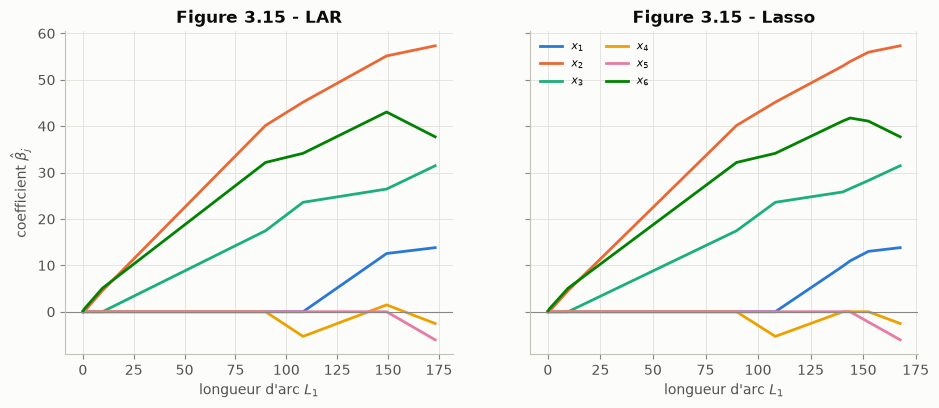

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (C, a, title) in zip(axes, [(coefs_lar, arc, "LAR"), (coefs_lasso, arc_lasso, "Lasso")]):
    for j in range(ps):
        ax.plot(a, C[:, j], color=COLORS[j], label="$x_%d$" % (j + 1))
    ax.axhline(0, color=GRAY, linewidth=0.8)
    ax.set_title("Figure 3.15 - %s" % title)
    ax.set_xlabel("longueur d'arc $L_1$")
axes[0].set_ylabel(r"coefficient $\hat\beta_j$")
axes[1].legend(ncol=2, fontsize=8)
plt.show()

Les deux profils coïncident jusqu'au moment où le coefficient de $x_4$ atteint zéro : LAR
le laisse changer de signe, le lasso le fait sortir de l'ensemble actif (il rentre plus
tard). Vérifions que LAR aboutit bien aux moindres carrés, et que notre chemin du lasso
coïncide avec celui de `sklearn.linear_model.lars_path` :

In [8]:
b_ls_sim = np.linalg.lstsq(Xsim, ysim, rcond=None)[0]
print("LAR, dernier nœud = moindres carrés ? écart = %.1e" % np.abs(coefs_lar[-1] - b_ls_sim).max())
_, _, sk = lars_path(Xsim, ysim, method="lasso")
print("lasso : %d nœuds (sklearn : %d), écart max = %.1e"
      % (len(coefs_lasso), sk.shape[1], np.abs(coefs_lasso - sk.T).max()))

LAR, dernier nœud = moindres carrés ? écart = 4.8e-13
lasso : 9 nœuds (sklearn : 9), écart max = 3.8e-13


**Sur la prostate**, aucun coefficient ne traverse zéro : LAR et lasso ont le même chemin,
atteint en 8 étapes (c'est aussi le chemin FS$_0$ de la figure 3.19 du livre).

In [9]:
C_lar_p, _, act_p = cr.lars(Xtr, ytr, method="lar")
C_las_p, _, act_lp = cr.lars(Xtr, ytr, method="lasso")
print("ordre d'entrée :", [names[j] for j in act_p])
print("chemins identiques ?", C_lar_p.shape == C_las_p.shape and np.allclose(C_lar_p, C_las_p))
print("dernier nœud = moindres carrés ?", np.allclose(C_lar_p[-1], fit_ls["coef"][1:]))

ordre d'entrée : ['lcavol', 'lweight', 'svi', 'pgg45', 'lbph', 'age', 'lcp', 'gleason']
chemins identiques ? True
dernier nœud = moindres carrés ? True


### 1.3 Degrés de liberté de LAR

Pour une méthode quelconque qui produit $\hat{\mathbf{y}}$ à partir de $\mathbf{y}$, le
livre définit les degrés de liberté (éq. (3.60)) :

$$
\mathrm{df}(\hat{\mathbf{y}}) = \frac{1}{\sigma^2}\sum_{i=1}^N \mathrm{Cov}(\hat y_i, y_i).
$$

Pour une méthode linéaire $\hat{\mathbf{y}} = \mathbf{H}\mathbf{y}$ ($\mathbf{H}$ fixe),
$\mathrm{Cov}(\hat y_i, y_i) = \sigma^2 H_{ii}$ et l'on retrouve $\mathrm{tr}(\mathbf{H})$.
Plus une méthode « colle » aux données, plus cette covariance est grande. Pour le meilleur
sous-ensemble à $k$ variables, $\mathrm{df}$ dépasse nettement $k$ (la recherche consomme
des degrés de liberté) ; pour **LAR après $k$ étapes**, de façon remarquable,
$\mathrm{df} = k$ (exactement ou presque). Vérifions-le par simulation.

In [10]:
rng = np.random.RandomState(0)
Xc_tr = Xtr - Xtr.mean(0)
mu = Xc_tr @ fit_ls["coef"][1:]
sigma = np.sqrt(fit_ls["sigma2"])
n_sim = 600
Y = mu + sigma * rng.randn(n_sim, N)
fits_lar = np.empty((n_sim, p + 1, N))
fits_bs = np.empty((n_sim, p + 1, N))
for b in range(n_sim):
    C_b, _, _ = cr.lars(Xc_tr, Y[b], method="lar")
    fits_lar[b] = Y[b].mean() + C_b @ Xc_tr.T          # ajustements aux 9 nœuds
    b0_b, B_b = cr.best_subset_path(Xc_tr, Y[b])
    fits_bs[b] = b0_b[:, None] + B_b @ Xc_tr.T


def df_hat(fits):
    """df estimé par sum_i Cov(yhat_i, y_i) / sigma^2 (éq. 3.60), constante comprise."""
    Yc = Y - Y.mean(0)
    return np.einsum("bkn,bn->k", fits - fits.mean(0), Yc) / (n_sim - 1) / sigma**2


df_lar, df_bs = df_hat(fits_lar), df_hat(fits_bs)

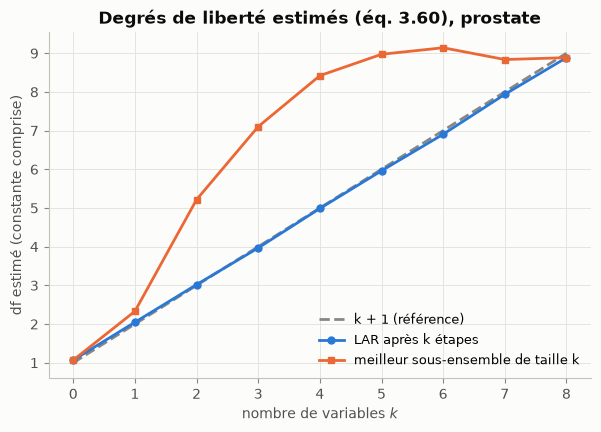

In [11]:
fig, ax = plt.subplots()
ks = np.arange(p + 1)
ax.plot(ks, ks + 1, color=GRAY, linestyle="--", label="k + 1 (référence)")
ax.plot(ks, df_lar, "o-", color=COLORS[0], label="LAR après k étapes")
ax.plot(ks, df_bs, "s-", color=COLORS[1], label="meilleur sous-ensemble de taille k")
ax.set_title("Degrés de liberté estimés (éq. 3.60), prostate")
ax.set_xlabel("nombre de variables $k$"); ax.set_ylabel("df estimé (constante comprise)")
ax.legend()
plt.show()

Avec la constante (qui compte pour un degré de liberté), LAR suit la diagonale $k+1$,
alors que le meilleur sous-ensemble la dépasse nettement pour les petites tailles : choisir
la *meilleure* variable parmi huit « coûte » plus qu'un paramètre.

## 2. Méthodes à directions dérivées

Lorsque les entrées sont nombreuses et corrélées, on peut d'abord construire un petit
nombre $M \le p$ de **combinaisons linéaires** $\mathbf{z}_m = \mathbf{X}\mathbf{w}_m$ des
entrées (standardisées), puis régresser $\mathbf{y}$ sur $\mathbf{z}_1, \dots, \mathbf{z}_M$
par moindres carrés. Les méthodes diffèrent par le choix des directions.

### 2.1 Régression sur composantes principales (PCR)

On prend pour $\mathbf{z}_m = \mathbf{X}\mathbf{v}_m$ les **composantes principales**
(cours 2, §4.2). Comme elles sont orthogonales, la régression est une somme de régressions
simples (éq. (3.61)) :

$$
\hat{\mathbf{y}}^{\mathrm{pcr}}_{(M)} = \bar y\,\mathbf{1} + \sum_{m=1}^M \hat\theta_m\,\mathbf{z}_m,
\qquad \hat\theta_m = \frac{\langle\mathbf{z}_m, \mathbf{y}\rangle}{\langle\mathbf{z}_m, \mathbf{z}_m\rangle}.
$$

Puisque $\mathbf{z}_m = \mathbf{X}\mathbf{v}_m$, on a
$\sum_m\hat\theta_m\mathbf{z}_m = \mathbf{X}\sum_m\hat\theta_m\mathbf{v}_m$, d'où les
coefficients sur les entrées d'origine (éq. (3.62), exercice 3.13) :
$\hat\beta^{\mathrm{pcr}}(M) = \sum_{m=1}^M\hat\theta_m\mathbf{v}_m$.

Pour $M = p$, les $\mathbf{z}_m$ engendrent tout l'espace des colonnes : on retrouve les
moindres carrés. Pour $M < p$, on obtient une régression réduite.

> **Intuition : PCR et ridge.** Les deux opèrent sur les composantes principales. Ridge
> **rétrécit** la $j$-ième de $d_j^2/(d_j^2 + \lambda)$ ; PCR **garde** intactes les $M$
> premières et **jette** les autres (facteur 1 ou 0). C'est la figure 3.17.

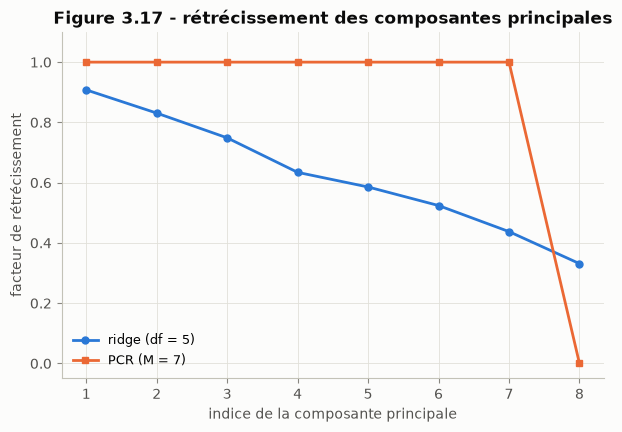

In [12]:
Xc = Xtr - Xtr.mean(0)
d = np.linalg.svd(Xc, compute_uv=False)
lam5 = cr.ridge_lambda_for_df(Xtr, 5.0)
fig, ax = plt.subplots()
idx = np.arange(1, p + 1)
ax.plot(idx, d**2 / (d**2 + lam5), "o-", color=COLORS[0], label=r"ridge (df = 5)")
ax.plot(idx, (idx <= 7).astype(float), "s-", color=COLORS[1], label="PCR (M = 7)")
ax.set_ylim(-0.05, 1.1)
ax.set_title("Figure 3.17 - rétrécissement des composantes principales")
ax.set_xlabel("indice de la composante principale"); ax.set_ylabel("facteur de rétrécissement")
ax.legend()
plt.show()

Les valeurs (df = 5 pour ridge, M = 7 pour PCR) sont celles choisies dans le livre.
Calculons le chemin PCR sur la prostate et vérifions qu'il aboutit aux moindres carrés.

In [13]:
b0_pcr, B_pcr = cr.pcr_path(Xtr, ytr)
print("PCR(M = p) = moindres carrés ?", np.allclose(B_pcr[-1], fit_ls["coef"][1:]))
pd.DataFrame(B_pcr[1:], columns=names, index=pd.Index(range(1, p + 1), name="M")).round(3)

PCR(M = p) = moindres carrés ? True


,lcavol,lweight,age,lbph,svi,lcp,gleason,pgg45
M,,,,,,,,
1,0.200,0.088,0.105,0.017,0.172,0.197,0.163,0.196
2,0.205,0.230,0.184,0.149,0.137,0.160,0.141,0.159
3,0.287,0.339,0.056,0.102,0.261,0.219,-0.016,0.062
4,0.273,0.344,-0.076,0.194,0.237,0.236,0.017,0.112
5,0.338,0.255,-0.058,0.266,0.246,0.251,-0.009,0.069
6,0.441,0.278,-0.082,0.219,0.132,0.252,0.017,0.047
7,0.551,0.289,-0.155,0.214,0.315,-0.062,0.228,-0.048
8,0.680,0.263,-0.141,0.210,0.305,-0.288,-0.021,0.267


### 2.2 Moindres carrés partiels (PLS)

PCR choisit ses directions **sans regarder $\mathbf{y}$**. Les moindres carrés partiels
utilisent aussi $\mathbf{y}$ (algorithme 3.3) :

1. Standardiser chaque $\mathbf{x}_j$ ; poser $\hat{\mathbf{y}}^{(0)} = \bar y\mathbf{1}$ et
   $\mathbf{x}_j^{(0)} = \mathbf{x}_j$.
2. Pour $m = 1, 2, \dots, p$ :
   - (a) $\mathbf{z}_m = \sum_j\hat\varphi_{mj}\mathbf{x}_j^{(m-1)}$, avec
     $\hat\varphi_{mj} = \langle\mathbf{x}_j^{(m-1)}, \mathbf{y}\rangle$ ;
   - (b) $\hat\theta_m = \langle\mathbf{z}_m, \mathbf{y}\rangle/\langle\mathbf{z}_m, \mathbf{z}_m\rangle$ ;
   - (c) $\hat{\mathbf{y}}^{(m)} = \hat{\mathbf{y}}^{(m-1)} + \hat\theta_m\mathbf{z}_m$ ;
   - (d) orthogonaliser chaque $\mathbf{x}_j^{(m-1)}$ par rapport à $\mathbf{z}_m$ :
     $\mathbf{x}_j^{(m)} = \mathbf{x}_j^{(m-1)} - \frac{\langle\mathbf{z}_m, \mathbf{x}_j^{(m-1)}\rangle}{\langle\mathbf{z}_m, \mathbf{z}_m\rangle}\mathbf{z}_m$.
3. Les $\hat{\mathbf{y}}^{(m)}$ étant linéaires en les $\mathbf{x}_j$, on récupère les
   coefficients $\hat\beta^{\mathrm{pls}}(m)$.

> **Intuition.** À la première étape, chaque entrée est pondérée par la force de son effet
> **univarié** sur $\mathbf{y}$ ($\hat\varphi_{1j} = \langle\mathbf{x}_j, \mathbf{y}\rangle$,
> proportionnel au coefficient de régression simple puisque les $\mathbf{x}_j$ sont
> standardisées). Les étapes suivantes répètent l'opération sur ce qui, dans les entrées,
> n'est pas encore expliqué par les directions précédentes.

Pour suivre les coefficients, `cr.pls_path` maintient une matrice $\mathbf{T}$ telle que
$\mathbf{X}^{(m)} = \mathbf{X}\mathbf{T}$ : chaque $\mathbf{z}_m = \mathbf{X}^{(m-1)}\hat\varphi_m = \mathbf{X}(\mathbf{T}\hat\varphi_m)$
s'exprime alors dans les variables d'origine.

In [14]:
b0_pls, B_pls, Zpls = cr.pls_path(Xtr, ytr)
G = Zpls.T @ Zpls
print("directions z_m orthogonales ? écart max hors diagonale relatif = %.1e"
      % (np.abs(G - np.diag(np.diag(G))).max() / np.diag(G).max()))
print("PLS(M = p) = moindres carrés ?", np.allclose(B_pls[-1], fit_ls["coef"][1:]))
pd.DataFrame(B_pls[1:], columns=names, index=pd.Index(range(1, p + 1), name="M")).round(3)

directions z_m orthogonales ? écart max hors diagonale relatif = 1.7e-17
PLS(M = p) = moindres carrés ? True


,lcavol,lweight,age,lbph,svi,lcp,gleason,pgg45
M,,,,,,,,
1,0.280,0.196,0.083,0.096,0.205,0.178,0.122,0.169
2,0.419,0.345,-0.026,0.220,0.243,0.078,0.011,0.084
3,0.576,0.279,-0.179,0.201,0.299,-0.036,0.006,0.117
4,0.672,0.250,-0.171,0.247,0.278,-0.223,0.055,0.188
5,0.683,0.267,-0.139,0.200,0.311,-0.287,0.015,0.223
6,0.673,0.267,-0.146,0.210,0.312,-0.291,-0.012,0.264
7,0.679,0.262,-0.141,0.211,0.307,-0.289,-0.021,0.266
8,0.680,0.263,-0.141,0.210,0.305,-0.288,-0.021,0.267


Comparons les prédictions à celles de `sklearn.cross_decomposition.PLSRegression` (sans
remise à l'échelle, puisque nos entrées sont déjà standardisées) :

In [15]:
for M in (1, 2, 3):
    sk = PLSRegression(n_components=M, scale=False).fit(Xtr, ytr)
    ecart = np.abs(b0_pls[M] + Xte @ B_pls[M] - sk.predict(Xte).ravel()).max()
    print("M = %d : écart max des prédictions avec sklearn = %.1e" % (M, ecart))

M = 1 : écart max des prédictions avec sklearn = 4.4e-16
M = 2 : écart max des prédictions avec sklearn = 1.3e-15
M = 3 : écart max des prédictions avec sklearn = 1.8e-15


### 2.3 Quel problème PLS résout-il ?

La $m$-ième direction principale $\mathbf{v}_m$ résout (éq. (3.63))

$$
\max_\alpha \mathrm{Var}(\mathbf{X}\alpha)\quad\text{sous}\quad \lVert\alpha\rVert = 1,\ \ \alpha^T\mathbf{S}\mathbf{v}_\ell = 0,\ \ \ell < m,
$$

(la contrainte $\alpha^T\mathbf{S}\mathbf{v}_\ell = 0$ rend $\mathbf{X}\alpha$ non corrélé
aux composantes précédentes), tandis que la $m$-ième direction PLS résout (éq. (3.64))

$$
\max_\alpha \mathrm{Corr}^2(\mathbf{y}, \mathbf{X}\alpha)\,\mathrm{Var}(\mathbf{X}\alpha)\quad\text{sous}\quad \lVert\alpha\rVert = 1,\ \ \alpha^T\mathbf{S}\hat\varphi_\ell = 0,\ \ \ell < m .
$$

PLS cherche donc des directions à la fois de **grande variance** et **corrélées à la
réponse** (exercice 3.15).

Pour $m = 1$, c'est immédiat : avec des données centrées,
$\mathrm{Corr}^2(\mathbf{y}, \mathbf{X}\alpha)\,\mathrm{Var}(\mathbf{X}\alpha) = \frac{\langle\mathbf{y}, \mathbf{X}\alpha\rangle^2}{N\,\lVert\mathbf{y}\rVert^2}$
(la variance de $\mathbf{X}\alpha$ se simplifie). Il faut maximiser
$\langle\mathbf{X}^T\mathbf{y}, \alpha\rangle^2$ sur la sphère unité : par Cauchy–Schwarz,
$\alpha \propto \mathbf{X}^T\mathbf{y} = \hat\varphi_1$. Vérification numérique par
directions aléatoires :

In [16]:
rng = np.random.RandomState(0)
yc = ytr - ytr.mean()
crit = lambda a: np.corrcoef(yc, Xc @ a)[0, 1] ** 2 * np.var(Xc @ a)
phi1 = Xc.T @ yc
phi1 /= np.linalg.norm(phi1)
v1 = np.linalg.svd(Xc, full_matrices=False)[2][0]
alphas = rng.randn(20000, p)
alphas /= np.linalg.norm(alphas, axis=1, keepdims=True)
print("critère (3.64) en phi_1            : %.4f" % crit(phi1))
print("max sur 20000 directions aléatoires: %.4f" % max(crit(a) for a in alphas))
print("critère en v_1 (1re comp. princ.)  : %.4f" % crit(v1))

critère (3.64) en phi_1            : 1.8724


max sur 20000 directions aléatoires: 1.7251


critère en v_1 (1re comp. princ.)  : 1.6661


> **Remarque.** Le livre note que l'aspect « variance » tend à dominer : en pratique PLS
> se comporte beaucoup comme ridge et PCR. Si les entrées sont orthogonales, PLS trouve les
> moindres carrés dès la première étape (exercice 3.14) ; plus généralement, la suite PLS
> coïncide avec celle du gradient conjugué appliqué aux équations normales (exercice 3.18).

## 3. Comparaison des méthodes sur la prostate

### 3.1 Courbes de validation croisée (figure 3.7)

On reprend le découpage en 10 plis du cours 2 (graine 12) et la règle « un écart-type ».
Pour chaque méthode, l'axe horizontal est orienté de sorte que la complexité augmente vers
la droite.

In [17]:
folds = cr.kfold_indices(N, K=10, rng=np.random.RandomState(12))
df_cv = np.linspace(0, p, 33)
s_cv = np.linspace(0, 1, 41)
methods = {
    "Meilleur sous-ensemble": (cr.best_subset_path, np.arange(p + 1), "taille du sous-ensemble"),
    "Ridge": (lambda X, y: cr.ridge_path_df(X, y, df_cv), df_cv, "degrés de liberté"),
    "Lasso": (lambda X, y: cr.lasso_path_s(X, y, s_cv), s_cv, "facteur de rétrécissement s"),
    "PCR": (cr.pcr_path, np.arange(p + 1), "nombre de directions"),
    "PLS": (cr.pls_path_coefs, np.arange(p + 1), "nombre de directions"),
}
cv_res = {}
for name, (fpath, grid, _) in methods.items():
    mean, se = cr.cv_error(fpath, Xtr, ytr, folds)
    cv_res[name] = (mean, se, cr.one_se_rule(mean, se))

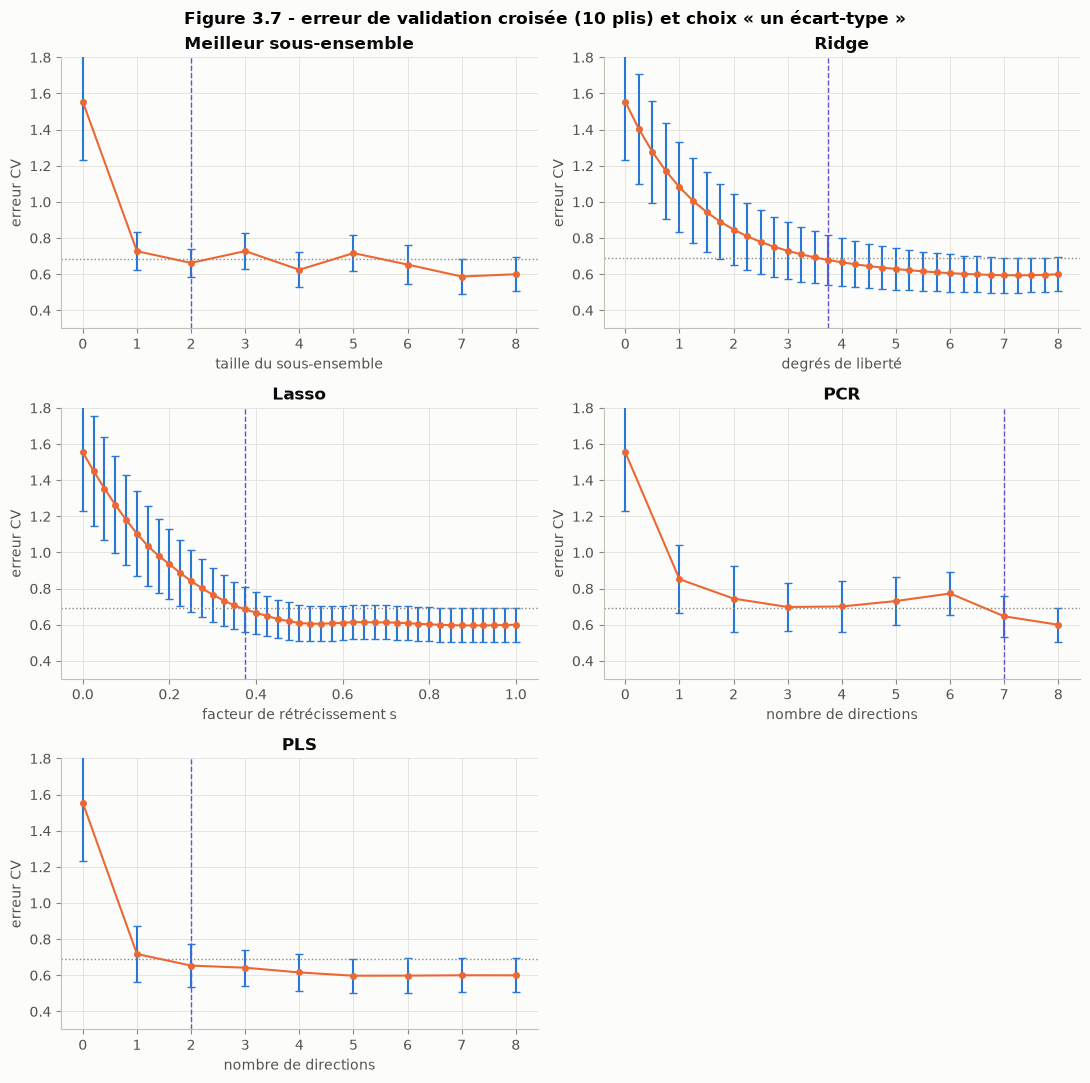

In [18]:
fig, axes = plt.subplots(3, 2, figsize=(11, 11))
for ax, (name, (fpath, grid, xlabel)) in zip(axes.ravel(), methods.items()):
    mean, se, i_best = cv_res[name]
    ax.errorbar(grid, mean, yerr=se, fmt="o-", color=ORANGE, ecolor=BLUE, capsize=3,
                markersize=4, linewidth=1.5)
    ax.axhline(mean.min() + se[np.argmin(mean)], color=GRAY, linestyle=":", linewidth=1)
    ax.axvline(grid[i_best], color=COLORS[6], linestyle="--", linewidth=1)
    ax.set_ylim(0.3, 1.8)
    ax.set_title(name); ax.set_xlabel(xlabel); ax.set_ylabel("erreur CV")
axes[2, 1].axis("off")
fig.suptitle("Figure 3.7 - erreur de validation croisée (10 plis) et choix « un écart-type »",
             fontweight="bold")
fig.tight_layout()
plt.show()

Toutes les courbes sont très **plates** près de leur minimum : de nombreux modèles sont
statistiquement indiscernables, d'où l'intérêt de la règle un écart-type qui retient le
plus simple.

### 3.2 Tableau 3.3

On ajuste chaque méthode sur tout l'échantillon d'apprentissage avec le paramètre choisi,
puis on mesure l'erreur sur les 30 observations de test, avec son erreur standard
$\mathrm{sd}\bigl((y_i - \hat y_i)^2\bigr)/\sqrt{30}$.

In [19]:
def fit_selected(name, i):
    fpath, grid, _ = methods[name]
    b0, B = fpath(Xtr, ytr)
    return b0[i], B[i], grid[i]


def column(b0, b):
    sq = (yte - b0 - Xte @ b) ** 2
    return np.r_[b0, b, sq.mean(), sq.std(ddof=1) / np.sqrt(len(yte))]


index = ["Intercept"] + names + ["Erreur de test", "Erreur std."]
cols, params = {"LS": column(fit_ls["coef"][0], fit_ls["coef"][1:])}, {}
for name in methods:
    b0, b, g = fit_selected(name, cv_res[name][2])
    cols[name] = column(b0, b)
    params[name] = g
table33 = pd.DataFrame(cols, index=index)
table33.loc[names] = table33.loc[names].where(np.abs(table33.loc[names]) > 1e-10)
print("paramètres retenus :", {k: round(float(v), 3) for k, v in params.items()})
show(table33)

paramètres retenus : {'Meilleur sous-ensemble': 2.0, 'Ridge': 3.75, 'Lasso': 0.375, 'PCR': 7.0, 'PLS': 2.0}


,LS,Meilleur sous-ensemble,Ridge,Lasso,PCR,PLS
Intercept,2.465,2.477,2.46,2.468,2.497,2.467
lcavol,0.68,0.74,0.324,0.538,0.551,0.419
lweight,0.263,0.316,0.208,0.188,0.289,0.345
age,-0.141,,-0.01,,-0.155,-0.026
lbph,0.21,,0.131,,0.214,0.22
svi,0.305,,0.191,0.085,0.315,0.243
lcp,-0.288,,0.058,,-0.062,0.078
gleason,-0.021,,0.05,,0.228,0.011
pgg45,0.267,,0.111,0.005,-0.048,0.084
Erreur de test,0.521,0.492,0.513,0.48,0.449,0.527


Pour comparaison, les valeurs du **tableau 3.3 du livre** (paramètres : sous-ensemble de
taille 2, ridge df = 5, lasso s = 0,36, PCR M = 7, PLS M = 2) :

In [20]:
book = pd.DataFrame({
    "LS": [2.465, 0.680, 0.263, -0.141, 0.210, 0.305, -0.288, -0.021, 0.267, 0.521, 0.179],
    "Meilleur sous-ensemble": [2.477, 0.740, 0.316, None, None, None, None, None, None, 0.492, 0.143],
    "Ridge": [2.452, 0.420, 0.238, -0.046, 0.162, 0.227, 0.000, 0.040, 0.133, 0.492, 0.165],
    "Lasso": [2.468, 0.533, 0.169, None, 0.002, 0.094, None, None, None, 0.479, 0.164],
    "PCR": [2.497, 0.543, 0.289, -0.152, 0.214, 0.315, -0.051, 0.232, -0.056, 0.449, 0.105],
    "PLS": [2.452, 0.419, 0.344, -0.026, 0.220, 0.243, 0.079, 0.011, 0.084, 0.528, 0.152],
}, index=index)
show(book)

,LS,Meilleur sous-ensemble,Ridge,Lasso,PCR,PLS
Intercept,2.465,2.477,2.452,2.468,2.497,2.452
lcavol,0.68,0.74,0.42,0.533,0.543,0.419
lweight,0.263,0.316,0.238,0.169,0.289,0.344
age,-0.141,,-0.046,,-0.152,-0.026
lbph,0.21,,0.162,0.002,0.214,0.22
svi,0.305,,0.227,0.094,0.315,0.243
lcp,-0.288,,0.0,,-0.051,0.079
gleason,-0.021,,0.04,,0.232,0.011
pgg45,0.267,,0.133,,-0.056,0.084
Erreur de test,0.521,0.492,0.492,0.479,0.449,0.528


Avec **exactement les paramètres du livre**, nos implémentations redonnent ses coefficients
(aux arrondis près ; pour le lasso, de petites différences sur les coefficients presque
nuls) :

In [21]:
at_book = {
    "Meilleur sous-ensemble": cr.subset_fit(Xtr, ytr, (0, 1)),
    "Ridge": cr.ridge_fit(Xtr, ytr, cr.ridge_lambda_for_df(Xtr, 5.0)),
    "Lasso": tuple(a[0] for a in cr.lasso_path_s(Xtr, ytr, [0.36])),
    "PCR": (b0_pcr[7], B_pcr[7]),
    "PLS": (b0_pls[2], B_pls[2]),
}
tab_book = pd.DataFrame({k: column(*v) for k, v in at_book.items()}, index=index)
tab_book.loc[names] = tab_book.loc[names].where(np.abs(tab_book.loc[names]) > 1e-10)
show(tab_book)

,Meilleur sous-ensemble,Ridge,Lasso,PCR,PLS
Intercept,2.477,2.464,2.469,2.497,2.467
lcavol,0.74,0.421,0.533,0.551,0.419
lweight,0.316,0.239,0.176,0.289,0.345
age,,-0.048,,-0.155,-0.026
lbph,,0.162,,0.214,0.22
svi,,0.227,0.074,0.315,0.243
lcp,,-0.0,,-0.062,0.078
gleason,,0.041,,0.228,0.011
pgg45,,0.132,,-0.048,0.084
Erreur de test,0.492,0.49,0.49,0.449,0.527


**Lecture.** Toutes les méthodes régularisées font au moins aussi bien que les moindres
carrés en test, mais les différences d'erreur de test (de l'ordre de 0,05) sont **bien
inférieures** à leurs erreurs standard (de l'ordre de 0,15) : avec 30 observations de test,
on ne peut pas départager sérieusement les méthodes. Le meilleur sous-ensemble et le lasso
donnent des modèles **parcimonieux** et donc plus interprétables.

### 3.3 Variabilité du choix par validation croisée

Le découpage en plis étant aléatoire, le paramètre choisi varie. Répétons la procédure avec
20 découpages différents :

In [22]:
choices = {name: [] for name in methods}
for seed in range(20):
    f_s = cr.kfold_indices(N, K=10, rng=np.random.RandomState(seed))
    for name, (fpath, grid, _) in methods.items():
        mean, se = cr.cv_error(fpath, Xtr, ytr, f_s)
        choices[name].append(round(float(grid[cr.one_se_rule(mean, se)]), 3))
summary = {k: ",  ".join("%g (%d)" % (v, c) for v, c in pd.Series(vals).value_counts().sort_index().items())
           for k, vals in choices.items()}
pd.Series(summary, name="valeur retenue (nombre de découpages sur 20)").to_frame()

,valeur retenue (nombre de découpages sur 20)
Meilleur sous-ensemble,"1 (5), 2 (13), 4 (1), 6 (1)"
Ridge,"2.75 (2), 3 (8), 3.25 (4), 3.5 (2), 3.75 (4)"
Lasso,"0.325 (2), 0.35 (4), 0.375 (11), 0.4 (2), 0.425 (1)"
PCR,"2 (3), 3 (15), 7 (2)"
PLS,"1 (12), 2 (8)"
